# OpenLex3D (Replica office0): RGB-D frames, rendered per-pixel object ids, tiered open-vocabulary labels

Combines the three pieces [OpenLex3D](https://github.com/openlex3d/openlex3d) uses for its Replica scenes:
- NICE-SLAM's `office0` sequence (RGB-D frames + camera poses): the trajectory OpenLex3D's predictions are built from.
- Replica's own `office_0/habitat/mesh_semantic.ply`: its per-face `object_id` is what OpenLex3D's labels index
  (`openlex3d/datasets/replica.py` reads it the same way).
- OpenLex3D's ground truth `gt_openlex3d/replica/office0/gt_categories.json`.

NICE-SLAM ships no semantics, so per-pixel object ids are rendered here by raycasting the semantic mesh from each
NICE-SLAM pose (Open3D's `RaycastingScene`). Needs `INSTALL.MD`'s OpenLex3D section run first, i.e.
`$HABITAT_DATA/openlex3d/gt_openlex3d`, `$HABITAT_DATA/replica/office_0` and `$HABITAT_DATA/replica/nice_slam/Replica/office0`.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
from PIL import Image

HABITAT_DATA = Path("/home/hcrassou/habitat_data/data")
REPLICA_SCENE = HABITAT_DATA / "replica" / "office_0"
NICE_SLAM = HABITAT_DATA / "replica" / "nice_slam" / "Replica"
SEQUENCE = NICE_SLAM / "office0"
GT = HABITAT_DATA / "openlex3d" / "gt_openlex3d" / "replica" / "office0"

CAMERA = json.load(open(NICE_SLAM / "cam_params.json"))["camera"]
POSES = np.loadtxt(SEQUENCE / "traj.txt").reshape(-1, 4, 4)
print(CAMERA)
print(len(POSES), "frames")
sorted(path.name for path in GT.iterdir()), sorted(path.name for path in (REPLICA_SCENE / "habitat").iterdir())

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


{'w': 1200, 'h': 680, 'fx': 600.0, 'fy': 600.0, 'cx': 599.5, 'cy': 339.5, 'scale': 6553.5}
2000 frames


(['gt_categories.json',
  'gt_categories_query_to_object_mapping_all.json',
  'gt_categories_query_to_object_mapping_l0.json',
  'gt_categories_query_to_object_mapping_l1.json',
  'gt_categories_w_queries.json',
  'gt_visible_cloud.pcd'],
 ['info_preseg_semantic.json',
  'info_semantic.json',
  'mesh_preseg_semantic.navmesh',
  'mesh_preseg_semantic.ply',
  'mesh_semantic.navmesh',
  'mesh_semantic.ply'])

## Layout

NICE-SLAM sequence (`nice_slam/Replica/office0/`), 2000 frames:
- `results/frame%06d.jpg`: 1200x680 RGB. `results/depth%06d.png`: uint16, metres x `cam_params.json`'s `scale` (6553.5).
- `traj.txt`: one row-major 4x4 camera-to-world matrix per line, in the Replica mesh's own frame (z up), with OpenCV
  camera axes (x right, y down, looking down +z).
- `../cam_params.json`: pinhole intrinsics shared by every Replica sequence (fx = fy = 600, centred principal point).

Replica scene (`replica/office_0/habitat/`):
- `mesh_semantic.ply`: the scene mesh with a per-face `object_id` (Replica's instance id).
- `info_semantic.json`: `objects` (`id`, `class_id`, `class_name`) and `classes`, Replica's own closed vocabulary.

Ground truth (`gt_openlex3d/replica/office0/`): the same schema as OpenLex3D's HM3D and ScanNet++ scenes.
- `gt_categories.json`: `dataset.samples`, one per labelled object: `object_id` (a `mesh_semantic.ply` face
  `object_id`) plus `labels.image_attributes` with the four tiers `synonyms`, `vis_sim`, `depictions`, `clutter` (other
  objects' ids as strings). Some objects have empty `synonyms`, and some carry `labels.flag == "ambiguous"`. OpenLex3D's
  own evaluation code reads neither.
- `gt_visible_cloud.pcd`: positions + colours only, no labels. It's the part of the mesh the NICE-SLAM trajectory
  sees; OpenLex3D labels its points by nearest-neighbour association to `mesh_semantic.ply` and scores only those.
- `gt_categories_w_queries.json` / `gt_categories_query_to_object_mapping_{l0,l1,all}.json`: text queries per object
  and their inverse (query -> object ids).

In [2]:
def read_frame(index: int) -> tuple[np.ndarray, np.ndarray]:
    """(rgb, depth in metres) for one NICE-SLAM frame."""
    rgb = np.array(Image.open(SEQUENCE / "results" / f"frame{index:06d}.jpg"))
    depth = np.array(Image.open(SEQUENCE / "results" / f"depth{index:06d}.png")) / CAMERA["scale"]
    return rgb, depth


GT_SAMPLES = json.load(open(GT / "gt_categories.json"))["dataset"]["samples"]
LABELS = {sample["object_id"]: sample["labels"]["image_attributes"] for sample in GT_SAMPLES}
AMBIGUOUS = {sample["object_id"] for sample in GT_SAMPLES if sample["labels"].get("flag") == "ambiguous"}
REPLICA_CLASSES = {obj["id"]: obj["class_name"] for obj in json.load(open(REPLICA_SCENE / "habitat" / "info_semantic.json"))["objects"]}


def display_name(object_id: int) -> str:
    """First OpenLex3D synonym, or Replica's own class in brackets when OpenLex3D gives none."""
    synonyms = LABELS[object_id]["synonyms"]
    return synonyms[0] if synonyms else f"[{REPLICA_CLASSES[object_id]}]"


print(f"{len(LABELS)} of {len(REPLICA_CLASSES)} Replica objects labelled")
print("ambiguous:", sorted(AMBIGUOUS))
print("empty synonyms:", {i: REPLICA_CLASSES[i] for i, labels in LABELS.items() if not labels["synonyms"]})
print("unlabelled, by Replica class:", Counter(REPLICA_CLASSES[i] for i in REPLICA_CLASSES if i not in LABELS).most_common(10))
LABELS[2]

57 of 64 Replica objects labelled
ambiguous: [2, 13, 14, 31, 32, 54, 64]
empty synonyms: {1: 'anonymize_text', 6: 'anonymize_text', 18: 'wall', 56: 'pillar', 55: 'undefined'}
unlabelled, by Replica class: [('other-leaf', 6), ('undefined', 1)]


{'synonyms': ['cushion', 'pillow', 'screen', 'tablet'],
 'vis_sim': ['book', 'box', 'container'],
 'depictions': [],
 'clutter': ['58', '64']}

## Per-pixel object ids from the semantic mesh

`mesh_semantic.ply` is binary with quad faces carrying an `object_id`. Each quad is split into two triangles for
Open3D's raycaster, and the hit triangle's id maps back to its quad's `object_id`. Rays use unnormalised camera-frame
directions `((u - cx) / fx, (v - cy) / fy, 1)`, so the returned hit distance is z-depth, directly comparable to
NICE-SLAM's depth images.

In [3]:
import re

VERTEX_DTYPE = np.dtype([("position", "<f4", 3), ("normal", "<f4", 3), ("color", "u1", 3)])
QUAD_DTYPE = np.dtype([("count", "u1"), ("indices", "<u4", 4), ("object_id", "<u2")])


def read_semantic_mesh(path: Path) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """(vertex positions, vertex colours in [0, 1], quad vertex indices, per-quad object_id) from Replica's mesh_semantic.ply."""
    raw = path.read_bytes()
    header_end = raw.index(b"end_header\n") + len(b"end_header\n")
    header = raw[:header_end].decode()
    vertex_count = int(re.search(r"element vertex (\d+)", header).group(1))
    face_count = int(re.search(r"element face (\d+)", header).group(1))
    vertices = np.frombuffer(raw, VERTEX_DTYPE, vertex_count, header_end)
    quads = np.frombuffer(raw, QUAD_DTYPE, face_count, header_end + vertex_count * VERTEX_DTYPE.itemsize)
    assert (quads["count"] == 4).all()
    return (
        vertices["position"].astype(np.float32),
        vertices["color"] / 255.0,
        quads["indices"].astype(np.uint32),
        quads["object_id"].astype(np.int32),
    )


MESH_VERTICES, MESH_COLORS, QUADS, QUAD_OBJECT_IDS = read_semantic_mesh(REPLICA_SCENE / "habitat" / "mesh_semantic.ply")
TRIANGLE_OBJECT_IDS = np.concatenate([QUAD_OBJECT_IDS, QUAD_OBJECT_IDS])
RAYCASTER = o3d.t.geometry.RaycastingScene()
RAYCASTER.add_triangles(
    o3d.core.Tensor(MESH_VERTICES), o3d.core.Tensor(np.concatenate([QUADS[:, [0, 1, 2]], QUADS[:, [0, 2, 3]]]))
)
_cols, _rows = np.meshgrid(np.arange(CAMERA["w"]), np.arange(CAMERA["h"]))
CAMERA_DIRECTIONS = np.stack(
    [(_cols - CAMERA["cx"]) / CAMERA["fx"], (_rows - CAMERA["cy"]) / CAMERA["fy"], np.ones_like(_cols, dtype=float)], -1
)


def render(index: int) -> tuple[np.ndarray, np.ndarray]:
    """(z-depth, object id with -1 where no hit) rendered from the semantic mesh at NICE-SLAM frame index's pose."""
    pose = POSES[index]
    directions = CAMERA_DIRECTIONS @ pose[:3, :3].T
    origins = np.broadcast_to(pose[:3, 3], directions.shape)
    hits = RAYCASTER.cast_rays(o3d.core.Tensor(np.concatenate([origins, directions], -1).astype(np.float32)))
    depth = hits["t_hit"].numpy()
    hit = np.isfinite(depth)
    object_ids = np.where(hit, TRIANGLE_OBJECT_IDS[np.where(hit, hits["primitive_ids"].numpy(), 0)], -1)
    return depth, object_ids


print(f"{len(MESH_VERTICES)} vertices, {len(QUADS)} quads, {len(np.unique(QUAD_OBJECT_IDS))} distinct object_ids on the mesh")

589517 vertices, 588759 quads, 68 distinct object_ids on the mesh


## Camera convention check

Renders depth from the semantic mesh at a few NICE-SLAM poses and compares it to NICE-SLAM's own depth. Agreement to a
few millimetres confirms that `traj.txt` is camera-to-world with OpenCV axes, already in `mesh_semantic.ply`'s frame,
and that `cam_params.json`'s intrinsics apply as-is.

In [4]:
for index in [0, 1000, 1999]:
    _, depth = read_frame(index)
    rendered_depth, _ = render(index)
    valid = (depth > 0) & np.isfinite(rendered_depth)
    error = np.abs(rendered_depth[valid] - depth[valid])
    print(f"frame {index}: median |rendered - NICE-SLAM depth| {np.median(error) * 1000:.1f} mm, 95th pct {np.percentile(error, 95) * 1000:.1f} mm")

frame 0: median |rendered - NICE-SLAM depth| 1.3 mm, 95th pct 3.5 mm
frame 1000: median |rendered - NICE-SLAM depth| 1.0 mm, 95th pct 3.1 mm
frame 1999: median |rendered - NICE-SLAM depth| 1.2 mm, 95th pct 4.8 mm


## Top-down map and trajectory

The semantic mesh's vertices seen from above (world z up), drawn bottom-up so furniture covers the floor, with the top
0.3 m below the highest vertex dropped to clip the ceiling. The camera path is drawn as a line through each pose's
translation, coloured by frame index, with its start and end marked. Arrows mark the frames shown in the examples
below, pointing along the camera's forward axis (+z column of the pose).

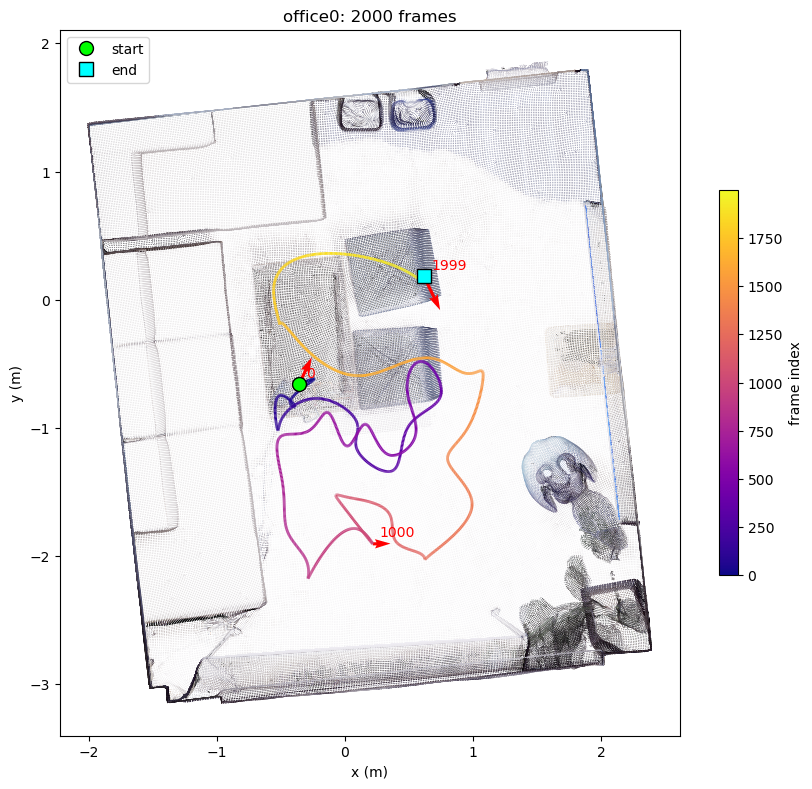

In [5]:
from matplotlib.collections import LineCollection

EXAMPLE_FRAMES = [0, 1000, 1999]

below_ceiling = MESH_VERTICES[:, 2] < MESH_VERTICES[:, 2].max() - 0.3
draw_order = np.argsort(MESH_VERTICES[below_ceiling, 2])

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(*MESH_VERTICES[below_ceiling][draw_order][:, :2].T, c=MESH_COLORS[below_ceiling][draw_order], s=0.3, linewidths=0)
positions = POSES[:, :2, 3]
path = LineCollection(np.stack([positions[:-1], positions[1:]], axis=1), cmap="plasma", linewidths=2)
path.set_array(np.arange(len(positions) - 1))
ax.add_collection(path)
ax.plot(*positions[0], "o", color="lime", markersize=10, markeredgecolor="black", label="start")
ax.plot(*positions[-1], "s", color="cyan", markersize=10, markeredgecolor="black", label="end")
forward = POSES[EXAMPLE_FRAMES, :2, 2]
ax.quiver(*positions[EXAMPLE_FRAMES].T, *forward.T, color="red", scale=15, width=0.005)
for frame in EXAMPLE_FRAMES:
    ax.annotate(str(frame), positions[frame], color="red", fontsize=10, xytext=(5, 5), textcoords="offset points")
ax.legend(loc="upper left")
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
fig.colorbar(path, ax=ax, shrink=0.5, label="frame index")
ax.set_title(f"{SEQUENCE.name}: {len(POSES)} frames")
plt.show()

## A few examples

Labelled objects' rendered masks drawn with detectron2's `Visualizer` (first synonym, or Replica's class in brackets
when OpenLex3D has no synonym), next to NICE-SLAM's depth and the raw rendered object ids (cycled through `tab20`, so
far-apart ids can share a colour). Unlabelled objects and pixels with no mesh hit stay undrawn.

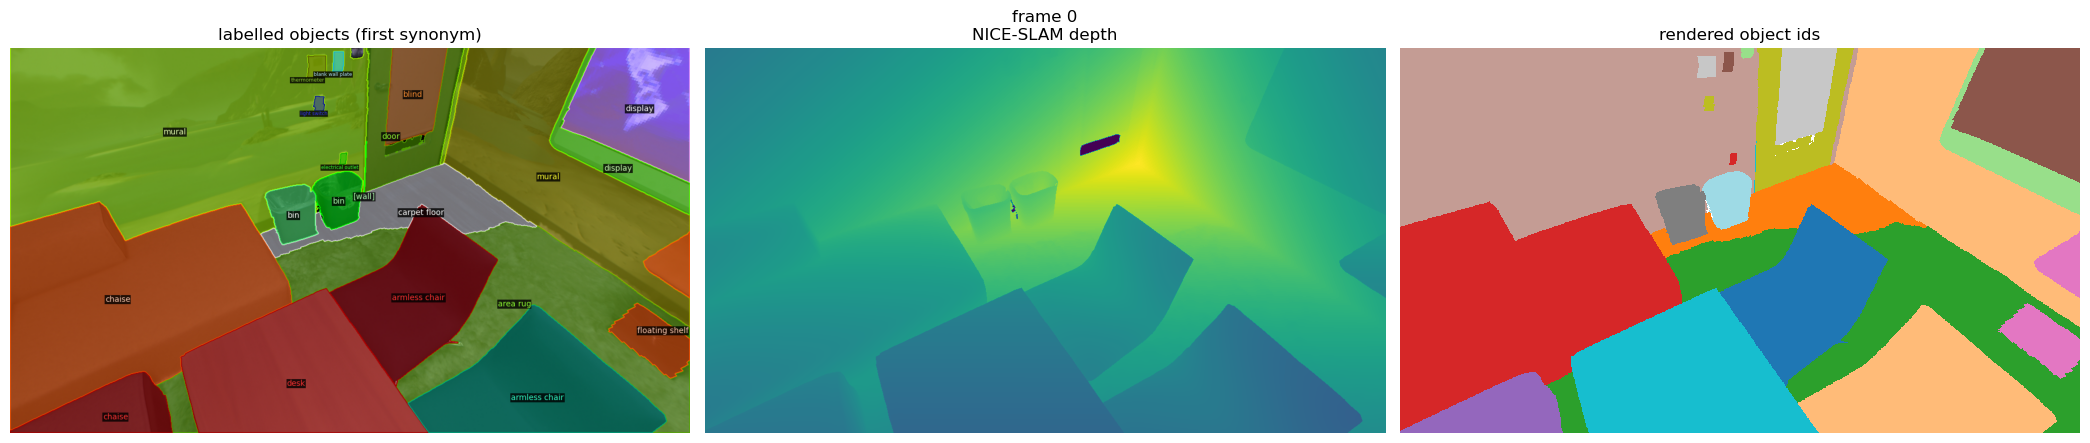

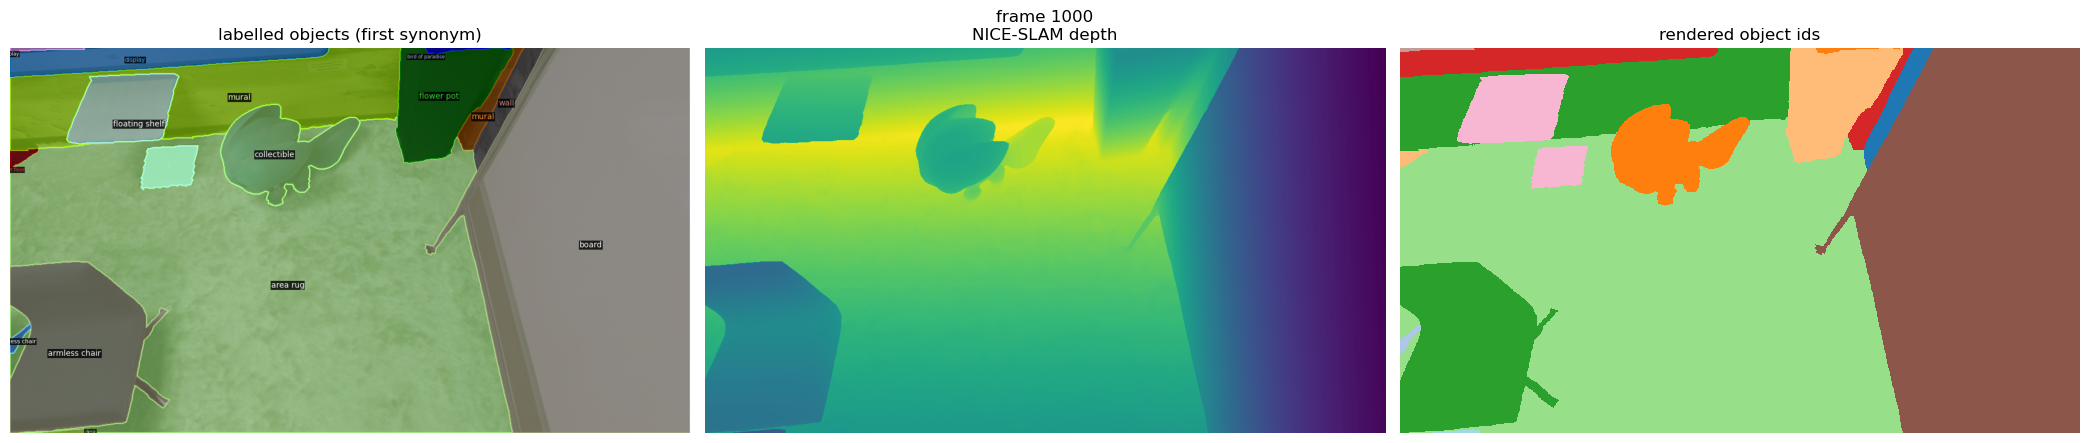

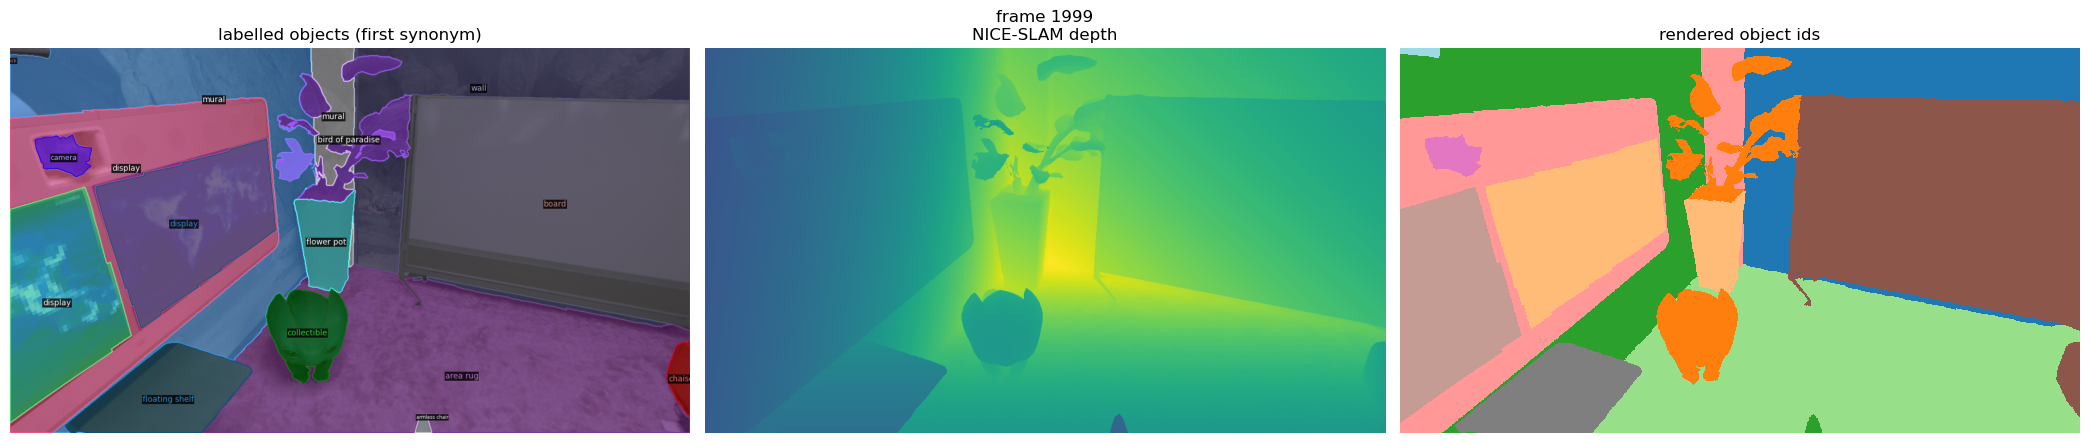

In [6]:
from detectron2.utils.visualizer import Visualizer


def show_example(index: int) -> None:
    rgb, depth = read_frame(index)
    _, object_ids = render(index)
    visible = [object_id for object_id in np.unique(object_ids) if object_id in LABELS]
    annotated = Visualizer(rgb).overlay_instances(
        masks=[object_ids == object_id for object_id in visible],
        labels=[display_name(object_id) for object_id in visible],
    ).get_image()

    _, axes = plt.subplots(1, 3, figsize=(21, 4.5))
    axes[0].imshow(annotated)
    axes[0].set_title("labelled objects (first synonym)")
    axes[1].imshow(depth, cmap="viridis")
    axes[1].set_title("NICE-SLAM depth")
    axes[2].imshow(np.where(object_ids < 0, np.nan, object_ids % 20), cmap="tab20", interpolation="nearest")
    axes[2].set_title("rendered object ids")
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"frame {index}")
    plt.tight_layout()
    plt.show()


for frame in EXAMPLE_FRAMES:
    show_example(frame)

## Label tiers for one object

The four largest views of one object with its full label tiers, `clutter` ids resolved to names. Commented out: it
renders every 10th frame to find the views.

In [7]:
# def largest_views(object_id: int, count: int = 4, stride: int = 10) -> list[tuple[int, np.ndarray]]:
#     views = [(index, render(index)[1] == object_id) for index in range(0, len(POSES), stride)]
#     return sorted(views, key=lambda view: -view[1].sum())[:count]
#
#
# def show_object(object_id: int) -> None:
#     labels = LABELS[object_id]
#     print(f"object {object_id} (Replica class: {REPLICA_CLASSES[object_id]}, ambiguous: {object_id in AMBIGUOUS})")
#     for tier in ["synonyms", "vis_sim", "depictions"]:
#         print(f"  {tier}: {labels[tier]}")
#     print(f"  clutter: {[display_name(int(i)) if int(i) in LABELS else REPLICA_CLASSES[int(i)] for i in labels['clutter']]}")
#
#     views = largest_views(object_id)
#     _, axes = plt.subplots(1, len(views), figsize=(5 * len(views), 5))
#     for ax, (index, mask) in zip(axes, views):
#         rows, cols = np.nonzero(mask)
#         margin = max(rows.ptp(), cols.ptp()) // 4
#         rgb, _ = read_frame(index)
#         ax.imshow(rgb[max(rows.min() - margin, 0):rows.max() + margin, max(cols.min() - margin, 0):cols.max() + margin])
#         ax.set_title(f"frame {index}")
#         ax.axis("off")
#     plt.tight_layout()
#     plt.show()
#
#
# show_object(2)

## Class frequency (per object)

Every labelled object in the scene counted once under its first synonym, whether or not or how often the trajectory
sees it. Objects with no synonym are left out (listed above).

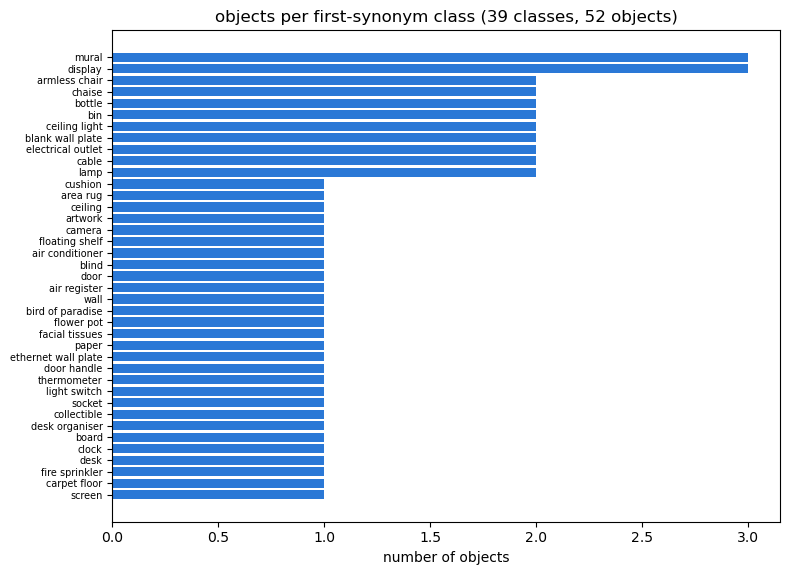

In [8]:
object_counts = Counter(labels["synonyms"][0] for labels in LABELS.values() if labels["synonyms"])
names, counts = zip(*object_counts.most_common())

fig, ax = plt.subplots(figsize=(8, max(4, len(names) * 0.15)))
ax.barh(range(len(names)), counts, color="#2a78d6")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("number of objects")
ax.set_title(f"objects per first-synonym class ({len(names)} classes, {sum(counts)} objects)")
plt.tight_layout()
plt.show()